# Policy gradient: from REINFORCE to SAC

**Code:** [`reinforce.py`](../algos/reinforce.py) · [`reinforce_baseline.py`](../algos/reinforce_baseline.py) · [`a2c.py`](../algos/a2c.py) · [`trpo.py`](../algos/trpo.py) · [`ppo.py`](../algos/ppo.py) · [`ddpg.py`](../algos/ddpg.py) · [`td3.py`](../algos/td3.py) · [`sac.py`](../algos/sac.py) · [`experiments/pg_variance.py`](../experiments/pg_variance.py) · [`experiments/policy_gradient_sweep.py`](../experiments/policy_gradient_sweep.py)
**Papers:** Williams 1992 ([PDF](../papers/policy-gradient/williams-1992-reinforce.pdf)), Sutton et al. 1999 ([PDF](../papers/policy-gradient/sutton-1999-policy-gradient.pdf)), Schulman 2015 GAE ([PDF](../papers/policy-gradient/schulman-2015-gae.pdf)), Mnih 2016 A3C ([PDF](../papers/policy-gradient/mnih-2016-a3c.pdf)), Schulman 2015 TRPO ([PDF](../papers/policy-gradient/schulman-2015-trpo.pdf)), Schulman 2017 PPO ([PDF](../papers/policy-gradient/schulman-2017-ppo.pdf)), Lillicrap 2015 DDPG ([PDF](../papers/policy-gradient/lillicrap-2015-ddpg.pdf)), Fujimoto 2018 TD3 ([PDF](../papers/policy-gradient/fujimoto-2018-td3.pdf)), Haarnoja 2018 SAC ([PDF](../papers/policy-gradient/haarnoja-2018-sac.pdf)) ·
**Notes:** [`papers/policy-gradient/notes.md`](../papers/policy-gradient/notes.md)

What you will see:

1. **Why baselines exist, measured:** at one frozen policy, the gradient's variance under four weightings. The learned baseline cuts it about twelvefold.
2. REINFORCE, REINFORCE + baseline, A2C, TRPO and PPO on CartPole at an equal budget of 100,000 steps, 5 seeds each.
3. **GAE's λ dial** from one-step TD (λ = 0) to Monte Carlo (λ = 1).
4. **PPO's clip under load:** the epoch count raised until the clip fraction shows it is working hard.
5. **TRPO's trust region:** the quadratic KL model against the real KL along one natural-gradient step, and the trust region size δ swept.
6. DDPG, TD3 and SAC on Pendulum; **TD3's three fixes removed one at a time**; **SAC's temperature** fixed against learned.
7. A trained SAC policy swinging the pendulum up, frame by frame.

Sections 2, 5, 6 (first half) and 8 run live (about 3 minutes on CPU). Sections 3, 4, 6 (second half) and 7 are 112 runs read from `experiments/results/policy_gradient/`;
`python experiments/policy_gradient_sweep.py <group>` regenerates them.

In [1]:
import json, pathlib, subprocess, sys, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import gymnasium as gym

from algos import a2c, ppo, sac
from algos.ddpg import evaluate_gym as evaluate_continuous

torch.set_num_threads(1)
plt.rcParams["figure.dpi"] = 110
ROOT = pathlib.Path("..") if pathlib.Path("../algos").exists() else pathlib.Path(".")
RESULTS = ROOT / "experiments/results/policy_gradient"

def load(group):
    rows = {}
    for path in sorted(RESULTS.glob(f"{group}__*.json")):
        r = json.loads(path.read_text()); rows.setdefault(r["name"], []).append(r)
    return rows

def curves(rows, title, ylabel="greedy return", ax=None, order=None):
    ax = ax or plt.subplots(figsize=(8, 3.6))[1]
    for name in (order or rows):
        results = rows[name]
        steps = [e["step"] for e in results[0]["log"]]
        n = min(len(r["log"]) for r in results)
        scores = np.array([[e["score"] for e in r["log"][:n]] for r in results])
        ax.plot(steps[:n], np.median(scores, 0), label=f"{name} ({len(results)})")
        ax.fill_between(steps[:n], scores.min(0), scores.max(0), alpha=0.12)
    ax.set_xlabel("environment steps"); ax.set_ylabel(ylabel); ax.set_title(title); ax.legend(fontsize=8)
    return ax

def table(rows, order=None):
    print(f"{'':>22} {'final, median [min, max]':>28} {'mean over curve':>16}")
    for name in (order or rows):
        results = rows[name]
        final = np.array([r["log"][-1]["score"] for r in results])
        area = np.median([np.mean([e["score"] for e in r["log"]]) for r in results])
        print(f"{name:>22} {f'{np.median(final):7.1f} [{final.min():7.1f}, {final.max():7.1f}]':>28} {area:>16.1f}")

## 0. The two problems

**CartPole-v1** (discrete): push a cart left or right to keep a pole up; +1 per step; at most 500. Observation: cart position, cart velocity, pole angle, pole angular velocity.

**Pendulum-v1** (continuous): a pendulum starts at a random angle and must be swung up and held upright with limited torque.

| column | meaning |
| --- | --- |
| `cos θ`, `sin θ` | the angle; upright is θ = 0, so cos θ = 1 |
| `θ̇` | angular velocity, −8 to 8 |
| action | one torque in [−2, 2] |
| reward | $-(\theta^2 + 0.1\,\dot\theta^2 + 0.001\,u^2)$, so 0 is best |

Episodes last 200 steps. A random policy scores about −1,200; −150 or better is solved.
The torque is too weak to lift the pendulum directly, so it has to be swung back and forth first.

  t   cos θ   sin θ      θ̇  torque   reward


  0  -0.859  -0.513  -0.526   0.548   -6.806
  1  -0.879  -0.477  -0.829  -0.921   -7.065
  2  -0.909  -0.417  -1.324  -1.836   -7.529
  3  -0.944  -0.329  -1.913  -1.934   -8.247
  4  -0.978  -0.211  -2.449   1.253   -9.181

random torque for 200 steps: return -1762.9


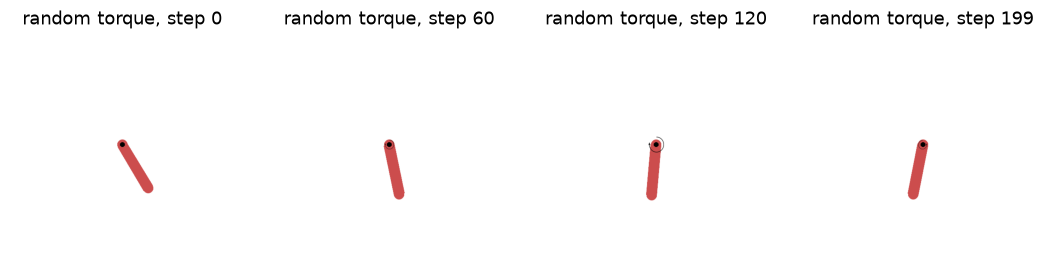

In [2]:
env = gym.make("Pendulum-v1", render_mode="rgb_array")
obs, _ = env.reset(seed=3)
rng = np.random.default_rng(0)
print(f"{'t':>3} {'cos θ':>7} {'sin θ':>7} {'θ̇':>7} {'torque':>7} {'reward':>8}")
frames = [env.render()]
total = 0.0
for t in range(200):
    action = rng.uniform(-2, 2, 1).astype(np.float32)
    nxt, reward, terminated, truncated, _ = env.step(action)
    total += reward
    if t < 5: print(f"{t:>3} {obs[0]:>7.3f} {obs[1]:>7.3f} {obs[2]:>7.3f} {action[0]:>7.3f} {reward:>8.3f}")
    if t in (60, 120, 199): frames.append(env.render())
    obs = nxt
print(f"\nrandom torque for 200 steps: return {total:.1f}")
fig, axs = plt.subplots(1, 4, figsize=(12, 3))
for ax, f, t in zip(axs, frames, (0, 60, 120, 199)):
    ax.imshow(f); ax.set_title(f"random torque, step {t}"); ax.axis("off")
plt.show()

## 1. The family in one picture

Two lineages. On the left, methods that adjust a stochastic policy along $\nabla \log\pi(a|s)\,\times$ something; each step replaces that "something" with a lower-variance estimate.
On the right, methods that get their policy from a learned Q function, because a continuous action has no `argmax`.
SAC sits in both: an actor-critic with a stochastic policy and twin Q critics.

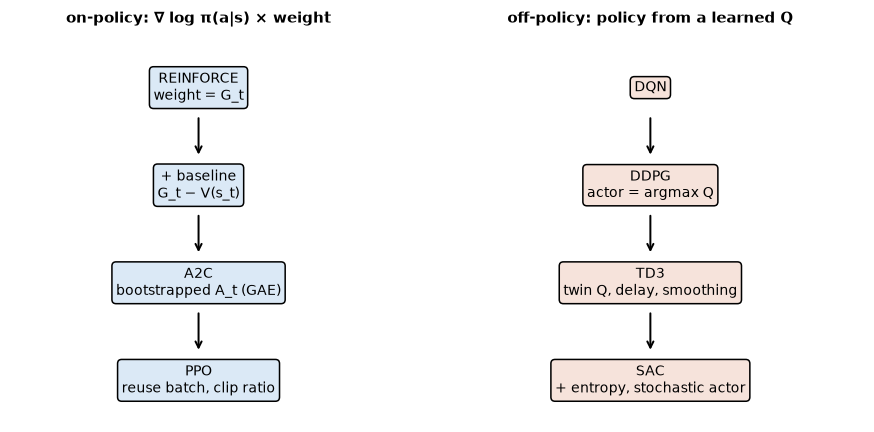

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.8)); ax.axis("off")
nodes = {"REINFORCE\nweight = G_t": (0.22, 0.82), "+ baseline\nG_t − V(s_t)": (0.22, 0.58), "A2C\nbootstrapped A_t (GAE)": (0.22, 0.34),
         "PPO\nreuse batch, clip ratio": (0.22, 0.1), "DQN": (0.75, 0.82), "DDPG\nactor = argmax Q": (0.75, 0.58),
         "TD3\ntwin Q, delay, smoothing": (0.75, 0.34), "SAC\n+ entropy, stochastic actor": (0.75, 0.1)}
for text, (x, y) in nodes.items():
    ax.text(x, y, text, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round", fc="#dbe9f6" if x < 0.5 else "#f6e3db"))
for a, b in [("REINFORCE\nweight = G_t", "+ baseline\nG_t − V(s_t)"), ("+ baseline\nG_t − V(s_t)", "A2C\nbootstrapped A_t (GAE)"),
             ("A2C\nbootstrapped A_t (GAE)", "PPO\nreuse batch, clip ratio"), ("DQN", "DDPG\nactor = argmax Q"),
             ("DDPG\nactor = argmax Q", "TD3\ntwin Q, delay, smoothing"), ("TD3\ntwin Q, delay, smoothing", "SAC\n+ entropy, stochastic actor")]:
    ax.annotate("", xy=nodes[b], xytext=nodes[a], arrowprops=dict(arrowstyle="->", lw=1.3, shrinkA=20, shrinkB=20))
ax.text(0.22, 0.98, "on-policy: ∇ log π(a|s) × weight", ha="center", fontsize=10, weight="bold")
ax.text(0.75, 0.98, "off-policy: policy from a learned Q", ha="center", fontsize=10, weight="bold")
plt.show()

## 2. Why baselines exist, measured

The policy gradient $\mathbb{E}[\nabla\log\pi(a_t|s_t)\,w_t]$ is unchanged if $w_t$ drops rewards that came before the action, or subtracts anything that depends only on the state.
So these four weightings have **the same expectation** and differ only in noise ([`experiments/pg_variance.py`](../experiments/pg_variance.py)).
One REINFORCE policy is frozen after 20,000 steps, and 300 independent one-episode gradients are drawn under each weighting.
**Cosine to mean** is how well one gradient estimate agrees with the average of all 300: how often a single update points the right way.


(0 s)


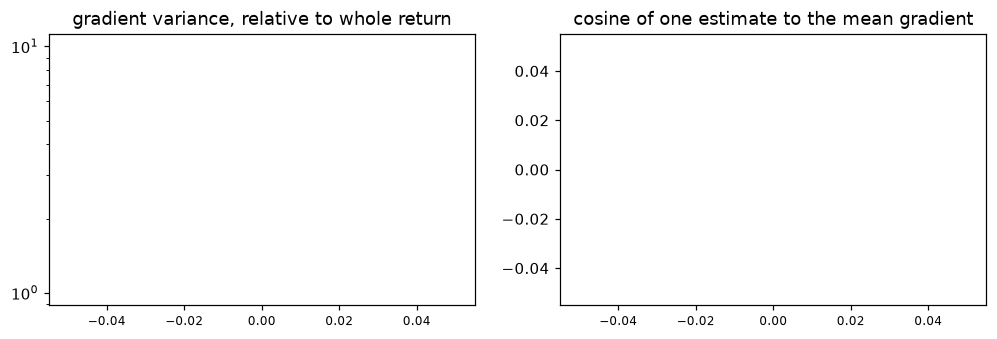

In [4]:
t0 = time.time()
out = subprocess.run([sys.executable, "-u", str(ROOT / "experiments/pg_variance.py")], capture_output=True, text=True,
                     cwd=ROOT, env={**__import__("os").environ, "PYTHONPATH": str(ROOT.resolve())})
lines = [l for l in out.stdout.splitlines() if l.strip()]
print("\n".join(lines)); print(f"({time.time() - t0:.0f} s)")
rows = [l.split() for l in lines if l.strip().split()[0] in ("whole", "reward-to-go", "minus")]
names = [" ".join(r[:-3]) for r in rows]
relative = [float(r[-2]) for r in rows]; cosine = [float(r[-1]) for r in rows]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
axs[0].bar(names, relative); axs[0].set_title("gradient variance, relative to whole return"); axs[0].set_yscale("log")
axs[1].bar(names, cosine, color="tab:green"); axs[1].set_title("cosine of one estimate to the mean gradient")
for ax in axs: ax.tick_params(axis="x", labelsize=8)
plt.show()

## 3. Five discrete methods, same budget

100,000 environment steps each on CartPole, 5 seeds. REINFORCE updates every 8 episodes; A2C every 32 steps; TRPO and PPO every 1,024 steps. TRPO takes one constrained natural-gradient step per batch; PPO takes 10 epochs of clipped minibatch steps.

                           final, median [min, max]  mean over curve
             REINFORCE     448.4 [  240.9,   496.1]            389.6
  REINFORCE + baseline     457.9 [  286.4,   500.0]            406.6
                   A2C     500.0 [  500.0,   500.0]            340.2
                  TRPO     500.0 [  500.0,   500.0]            497.6
                   PPO     500.0 [  500.0,   500.0]            467.9


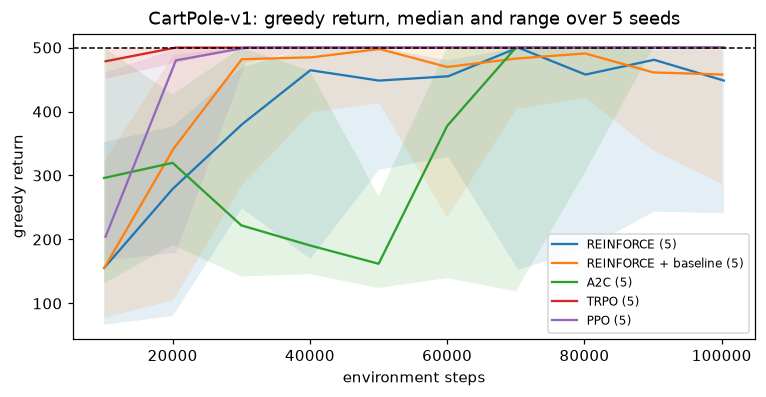

In [5]:
order = ["REINFORCE", "REINFORCE + baseline", "A2C", "TRPO", "PPO"]
discrete = load("discrete")
table(discrete, order)
ax = curves(discrete, "CartPole-v1: greedy return, median and range over 5 seeds", order=order)
ax.axhline(500, color="k", ls="--", lw=1); plt.show()

- **TRPO** is the best of the five: 500 on all 5 seeds and a curve average of 497.6, so it is at 500 almost from the first evaluation.
- **PPO** also ends at 500 on all 5 seeds, curve average 467.9. Engstrom et al. 2020 (`papers/practice/`) found PPO's lead over TRPO on MuJoCo came mostly from code-level details; on CartPole at this budget the order is reversed. One task, 5 seeds, so not a general ranking.
- **A2C** also ends at 500 on every seed but starts slower (curve average 340.2).
- **The baseline** lifts REINFORCE's curve average from 389.6 to 406.6. That is less than section 2's twelvefold variance cut suggests, because Adam already rescales the noisy gradient's step size.
- **Plain REINFORCE** gets there too on CartPole, but its final returns range from 240.9 to 496.1.

The "Adam rescales" point is a HYPOTHESIS (unverified); a run with plain SGD would test it.

## 4. GAE's λ: one dial from TD to Monte Carlo

$\hat A_t = \sum_k (\gamma\lambda)^k \delta_{t+k}$ with $\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$ ([`algos/a2c.py:103-114`](../algos/a2c.py)).
λ = 0 is the one-step TD error: low variance, but only as right as the critic. λ = 1 is the Monte Carlo return minus V: unbiased, noisy.
PPO, 3 seeds per λ.

                           final, median [min, max]  mean over curve
            lambda=0.0     500.0 [  130.7,   500.0]            247.0
            lambda=0.5     500.0 [  500.0,   500.0]            363.2
            lambda=0.9     500.0 [  500.0,   500.0]            479.3
           lambda=0.95     500.0 [  500.0,   500.0]            481.8
            lambda=1.0     500.0 [  500.0,   500.0]            475.8


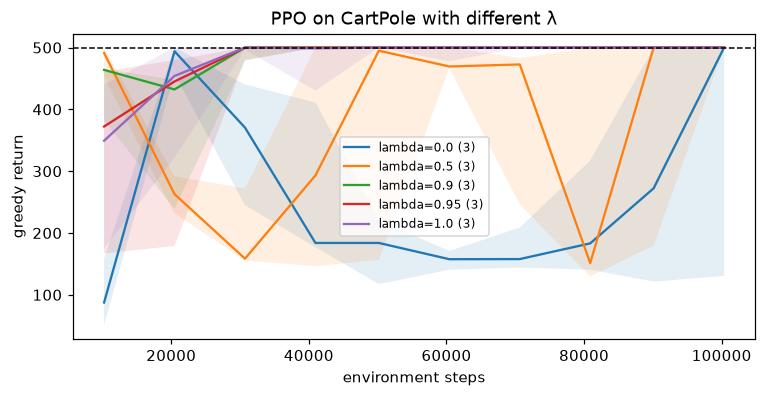

In [6]:
gae_rows = load("gae")
gae_order = [f"lambda={l}" for l in (0.0, 0.5, 0.9, 0.95, 1.0)]
table(gae_rows, gae_order)
ax = curves(gae_rows, "PPO on CartPole with different λ", order=gae_order); ax.axhline(500, color="k", ls="--", lw=1); plt.show()

λ = 0 (pure one-step TD) is clearly worst: curve average 247.0, and one seed ends at 130.7. The critic is wrong early, and λ = 0 trusts it completely.
From λ = 0.9 to λ = 1 the curve averages are 479.3, 481.8 and 475.8, which is within seed noise.
On CartPole the bias of a short estimate costs more than the variance of a long one.

## 5. PPO's clip, under load

PPO reuses each batch for several epochs. The ratio $r = \pi_\theta/\pi_{old}$ starts at 1 and drifts as the policy changes; the clip zeroes the gradient once it leaves $[0.8, 1.2]$ in the improving direction.
Raise the number of epochs and the policy tries to move further per batch: the **clip fraction** (share of samples outside the range) and **approx KL** show how hard the clip is working.
One seed per setting, 30,720 steps, live.

(22 s)


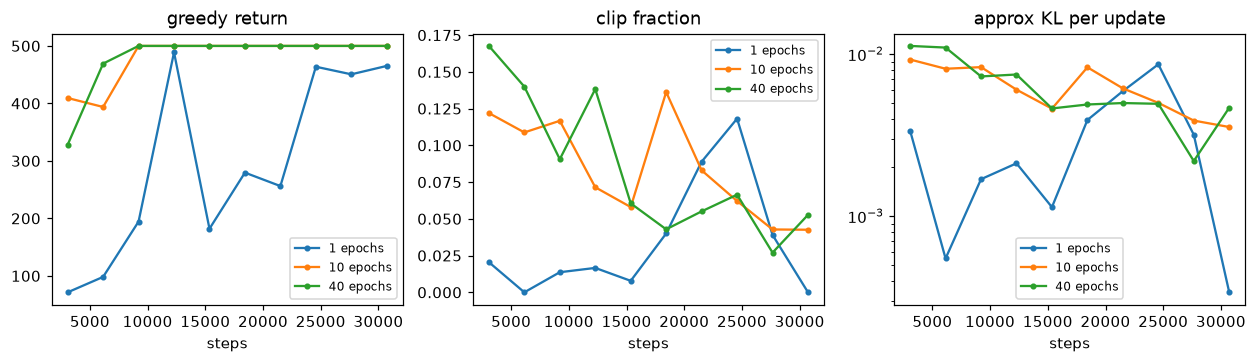

epochs  first: clip frac  first: KL  last: clip frac  last: KL  final greedy
     1             0.021     0.0034            0.000    0.0003         465.2
    10             0.122     0.0093            0.043    0.0035         500.0
    40             0.168     0.0112            0.053    0.0047         500.0


In [7]:
make = lambda: gym.make("CartPole-v1")
t0 = time.time()
runs = {}
for epochs in (1, 10, 40):
    _, log = ppo.train(make(), total_steps=30_720, epochs=epochs, learning_rate=1e-3,
                       evaluate=a2c.evaluate_gym(make, episodes=5), eval_every=3_072, seed=0)
    runs[epochs] = log
print(f"({time.time() - t0:.0f} s)")
fig, axs = plt.subplots(1, 3, figsize=(14, 3.2))
for epochs, log in runs.items():
    steps = [r["step"] for r in log]
    axs[0].plot(steps, [r["score"] for r in log], "o-", ms=3, label=f"{epochs} epochs")
    axs[1].plot(steps, [r["clip_fraction"] for r in log], "o-", ms=3, label=f"{epochs} epochs")
    axs[2].plot(steps, [r["approx_kl"] for r in log], "o-", ms=3, label=f"{epochs} epochs")
for ax, t in zip(axs, ["greedy return", "clip fraction", "approx KL per update"]):
    ax.set_title(t); ax.set_xlabel("steps"); ax.legend(fontsize=8)
axs[2].set_yscale("log"); plt.show()
# First and last update, not the mean over the run: the mean hides the shape.
# Measured while building this notebook, 10 and 40 epochs have the same run-mean
# clip fraction (0.084) and KL (0.0063) with clearly different curves.
print(f"{'epochs':>6} {'first: clip frac':>17} {'first: KL':>10} {'last: clip frac':>16} {'last: KL':>9} {'final greedy':>13}")
for epochs, log in runs.items():
    print(f"{epochs:>6} {log[0]['clip_fraction']:>17.3f} {log[0]['approx_kl']:>10.4f} {log[-1]['clip_fraction']:>16.3f} "
          f"{log[-1]['approx_kl']:>9.4f} {log[-1]['score']:>13.1f}")

More epochs push the policy further per batch, and the clip fraction shows it. At the first update, 1 epoch puts 2% of samples outside the clip range, 10 epochs 12%, and 40 epochs 17%.
The approximate KL rises much less: 0.0034, 0.0093 and 0.0112. Four times the epochs moves the policy about 20% further, because once a sample leaves the clip range its gradient is zero.
That is the clip doing its job. All three runs learn: 1 epoch ends at 465.2, and 10 and 40 epochs at 500.

The table shows the first and last update rather than a mean over the run. Averaged over the whole run, 10 and 40 epochs both come to clip fraction 0.084 and KL 0.0063, because 40 epochs is higher early and lower late. A run-mean would have suggested the setting does nothing.

## 6. TRPO's trust region

TRPO solves $\max_\theta L(\theta)$ subject to $\overline{KL}(\pi_{old}\,\|\,\pi_\theta) \le \delta$ to second order ([`algos/trpo.py`](../algos/trpo.py)):
the direction is the natural gradient $x = F^{-1} g$, found by conjugate gradient from Fisher-vector products alone, and its length is chosen so the **quadratic model** of the KL, $\tfrac12 s^2\, x^\top F x$, equals δ.
Below, one batch from an untrained policy: the real KL and the real surrogate improvement along that direction, against the model.
Where the two KL curves part, the line search has to step back.

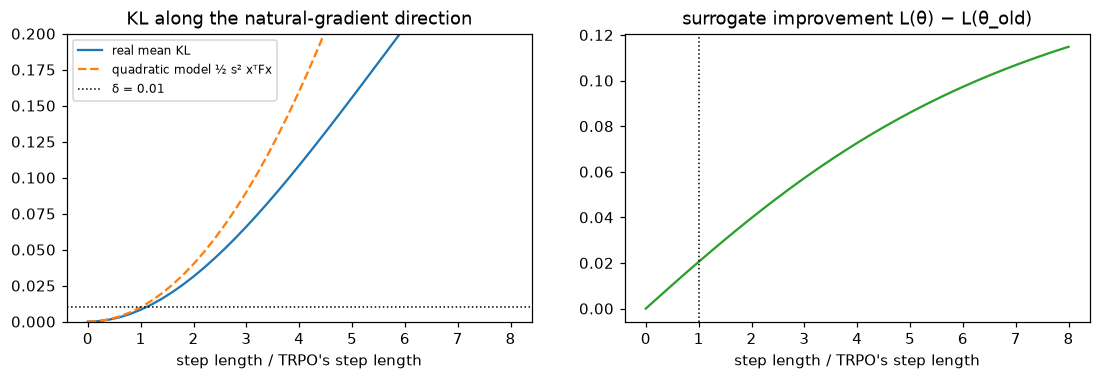

at TRPO's step: model KL 0.01, real KL 0.0082, surrogate gain 0.0205


In [8]:
from algos import trpo
make = lambda: gym.make("CartPole-v1")
torch.manual_seed(0)
model = a2c.ActorCritic(4, 2)
batch = a2c.collect(a2c.Rollout(make(), 0), model, 1_024)
adv, _ = a2c.gae(batch); adv = (adv - adv.mean()) / (adv.std() + 1e-8)
obs, actions, old_logp = batch["obs"], batch["actions"], batch["logp"]
params = list(model.actor.parameters())
old = torch.distributions.Categorical(logits=model.actor(obs).detach())
surrogate = lambda: (torch.exp(model.distribution(obs).log_prob(actions) - old_logp) * adv).mean()
mean_kl = lambda: torch.distributions.kl_divergence(old, model.distribution(obs)).mean()
fvp = lambda v: trpo.flat_grad(trpo.flat_grad(mean_kl(), params, create_graph=True) @ v, params) + trpo.DAMPING * v
g = trpo.flat_grad(surrogate(), params)
x = trpo.conjugate_gradient(fvp, g)
xFx = float(x @ fvp(x))
theta0 = torch.cat([p.data.reshape(-1) for p in params])
scales = np.linspace(0, 8 * np.sqrt(2 * trpo.MAX_KL / xFx), 41)
real_kl, gain = [], []
for scale in scales:
    trpo.set_flat(params, theta0 + scale * x)
    with torch.no_grad():
        real_kl.append(float(mean_kl())); gain.append(float(surrogate()))
trpo.set_flat(params, theta0)
s_star = np.sqrt(2 * trpo.MAX_KL / xFx)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
axs[0].plot(scales / s_star, real_kl, label="real mean KL"); axs[0].plot(scales / s_star, 0.5 * scales**2 * xFx, "--", label="quadratic model ½ s² xᵀFx")
axs[0].axhline(trpo.MAX_KL, color="k", lw=1, ls=":", label=f"δ = {trpo.MAX_KL}"); axs[0].set_ylim(0, 0.2)
axs[1].plot(scales / s_star, np.array(gain) - gain[0], color="tab:green"); axs[1].axvline(1, color="k", lw=1, ls=":")
axs[0].set_title("KL along the natural-gradient direction"); axs[1].set_title("surrogate improvement L(θ) − L(θ_old)")
for ax in axs: ax.set_xlabel("step length / TRPO's step length"); ax.legend(fontsize=8) if ax is axs[0] else None
plt.show()
i = int(np.argmin(np.abs(scales / s_star - 1)))
print(f"at TRPO's step: model KL {trpo.MAX_KL}, real KL {real_kl[i]:.4f}, surrogate gain {gain[i] - gain[0]:.4f}")

δ sets how far each update may move the policy. 3 seeds per δ, CartPole, 100,000 steps.
The right panel is the KL of the step TRPO actually accepted, at each evaluation; the dotted lines are the δ limits.

                           final, median [min, max]  mean over curve
           delta=0.001     500.0 [  500.0,   500.0]            476.0
            delta=0.01     500.0 [  500.0,   500.0]            499.6
            delta=0.05     500.0 [  500.0,   500.0]            492.9
             delta=0.2     500.0 [  450.2,   500.0]            474.8


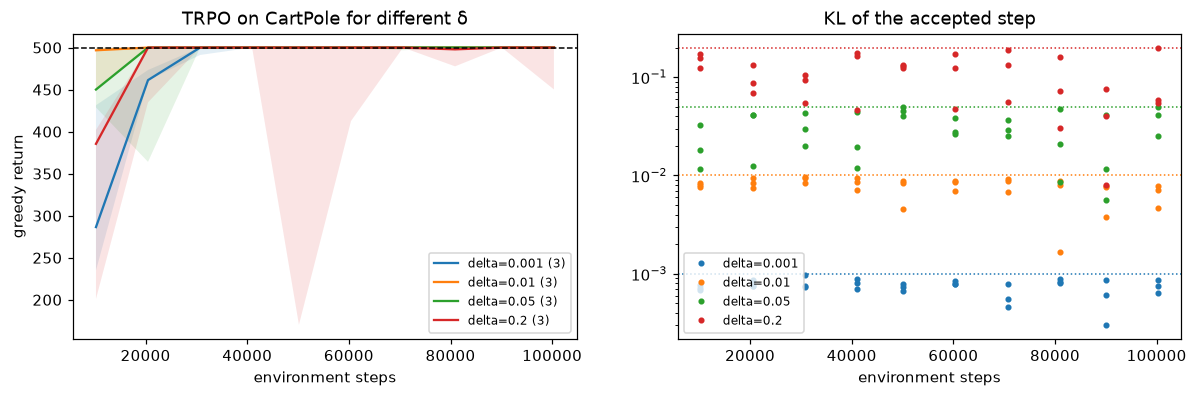

largest accepted KL over every update logged: delta=0.001: 0.0010, delta=0.01: 0.0095, delta=0.05: 0.0499, delta=0.2: 0.1979
delta=0.2: lowest greedy return after the first evaluation 170


In [9]:
kl_rows = load("trpo_kl")
kl_order = [f"delta={d}" for d in (0.001, 0.01, 0.05, 0.2)]
table(kl_rows, kl_order)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
curves(kl_rows, "TRPO on CartPole for different δ", ax=axs[0], order=kl_order); axs[0].axhline(500, color="k", ls="--", lw=1)
for k, name in enumerate(kl_order):
    for r in kl_rows[name]:
        axs[1].plot([e["step"] for e in r["log"]], [e["kl"] for e in r["log"]], "o", ms=3, color=f"C{k}",
                    label=name if r is kl_rows[name][0] else None)
    axs[1].axhline(float(name.split("=")[1]), color=f"C{k}", ls=":", lw=1)
axs[1].set_yscale("log"); axs[1].set_title("KL of the accepted step"); axs[1].set_xlabel("environment steps"); axs[1].legend(fontsize=8)
plt.show()
low = min(e["score"] for r in kl_rows["delta=0.2"] for e in r["log"][1:])
print(f"largest accepted KL over every update logged: " +
      ", ".join(f"{n}: {max(e['kl'] for r in kl_rows[n] for e in r['log']):.4f}" for n in kl_order))
print(f"delta=0.2: lowest greedy return after the first evaluation {low:.0f}")

- **δ = 0.001** is the slowest start: the first evaluations are 235, 431 and 286, against 451 to 500 for δ = 0.01.
- **δ = 0.2** learns, then falls back: its returns after reaching 500 drop to 170, 413 and 450. The line search still holds every accepted KL below δ, but δ itself allows a large change.
- **δ = 0.01**, the paper's value, has the best curve average, 499.6.
- The accepted KL never exceeds δ in any logged update. That is the guarantee PPO gives up for a `clamp`.

## 7. Continuous control: DDPG, TD3, SAC on Pendulum

20,000 steps, 5 seeds, evaluated with the deterministic action (no exploration noise) over 5 episodes every 2,000 steps.

                           final, median [min, max]  mean over curve
                  DDPG    -104.2 [ -110.5,   -98.2]           -225.3
                   TD3     -97.1 [  -97.7,   -96.6]           -397.8
                   SAC     -97.1 [  -98.9,   -96.2]           -278.9


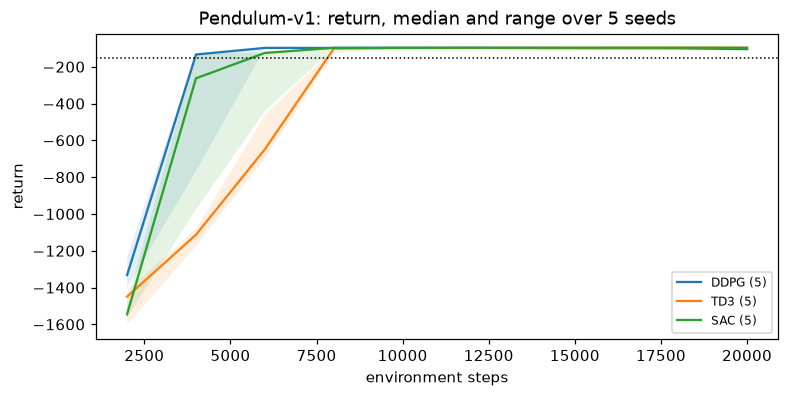

In [10]:
cont = load("continuous")
table(cont, ["DDPG", "TD3", "SAC"])
ax = curves(cont, "Pendulum-v1: return, median and range over 5 seeds", ylabel="return", order=["DDPG", "TD3", "SAC"])
ax.axhline(-150, color="k", ls=":", lw=1); plt.show()

All three reach about −100 by 20,000 steps; Pendulum does not separate them at the end.
They differ in speed: DDPG and SAC reach −200 in 4,000 to 6,000 steps, and TD3 takes 8,000 on all 5 seeds.
DDPG ends slightly worse and more spread out: −104.2 [−110.5, −98.2] against −97.1 for both others.

### TD3's three fixes, removed one at a time

| removed | argument | what it fixes |
| --- | --- | --- |
| clipped double Q | `n_critics=1` | target uses the smaller of two critics, so overestimation is not chased |
| delayed actor | `policy_delay=1` | actor updates every 2nd critic step, on a critic that has settled |
| target smoothing | `target_noise=0` | target averages Q over nearby actions, so narrow critic spikes are not exploited |

                           final, median [min, max]  mean over curve
       TD3 (all three)     -97.1 [  -97.7,   -96.6]           -397.8
   no clipped double Q     -96.7 [ -123.8,   -96.5]           -392.2
              no delay     -96.9 [  -97.4,   -96.6]           -241.1
   no target smoothing     -96.7 [  -97.4,   -96.4]           -396.6
          none of them     -97.6 [ -101.5,   -97.1]           -238.6


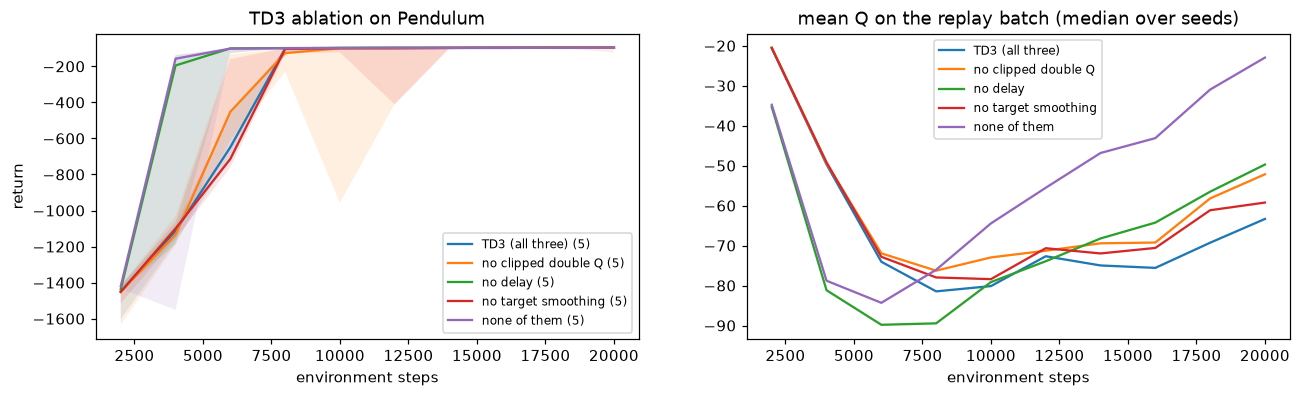

In [11]:
td3_order = ["TD3 (all three)", "no clipped double Q", "no delay", "no target smoothing", "none of them"]
td3_rows = load("td3_ablation")
table(td3_rows, td3_order)
fig, axs = plt.subplots(1, 2, figsize=(14, 3.6))
curves(td3_rows, "TD3 ablation on Pendulum", ylabel="return", ax=axs[0], order=td3_order)
for name in td3_order:
    results = td3_rows[name]
    q = np.array([[e["q"] for e in r["log"]] for r in results])
    axs[1].plot([e["step"] for e in results[0]["log"]], np.median(q, 0), label=name)
axs[1].set_title("mean Q on the replay batch (median over seeds)"); axs[1].set_xlabel("environment steps"); axs[1].legend(fontsize=8)
plt.show()

Every variant ends at about −97, so on Pendulum none of TD3's fixes changes the final **return**.
The delayed actor is the only one with a measurable effect on the return, and it is a **cost**: with it, −200 takes 8,000 steps on every seed; without it, 4,000 to 6,000.

The critic tells a different story (right panel). Final mean Q on the replay batch, median over 5 seeds:
full TD3 −63.3, no target smoothing −59.2, no clipped double Q −52.2, no delay −49.7, **none of them −23.0** (every seed between −28.2 and −22.8).
Each fix pulls the critic's values down, and together they pull them down by about 40. That is the direction the fixes are designed to push.
Whether the higher values are *over*estimates needs the true value of the buffer states, which these runs do not compute.
On Pendulum the actor does not turn the difference into a worse return within 20,000 steps.

### SAC's temperature

α prices randomness. Fixed at 0.01 the policy is nearly deterministic; at 1 it is paid to stay random. Learned, α is adjusted to hold the policy's entropy near −1 (minus the action dimension).

                           final, median [min, max]  mean over curve
         learned alpha     -97.1 [  -98.9,   -96.2]           -278.9
            alpha=0.01     -98.1 [  -98.5,   -97.1]           -268.6
             alpha=0.1     -98.4 [  -99.3,   -97.6]           -285.1
               alpha=1    -121.3 [ -122.0,  -120.4]           -303.5


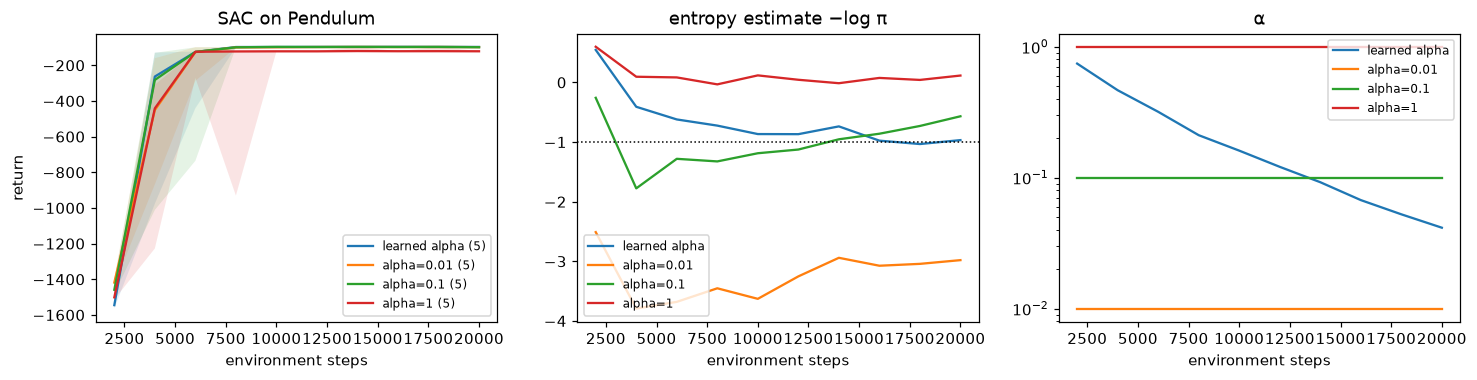

In [12]:
sac_order = ["learned alpha", "alpha=0.01", "alpha=0.1", "alpha=1"]
sac_rows = load("sac_alpha")
table(sac_rows, sac_order)
fig, axs = plt.subplots(1, 3, figsize=(16, 3.4))
curves(sac_rows, "SAC on Pendulum", ylabel="return", ax=axs[0], order=sac_order)
for key, ax, title in (("entropy", axs[1], "entropy estimate −log π"), ("alpha", axs[2], "α")):
    for name in sac_order:
        results = sac_rows[name]
        v = np.array([[e[key] for e in r["log"]] for r in results])
        ax.plot([e["step"] for e in results[0]["log"]], np.median(v, 0), label=name)
    ax.set_title(title); ax.set_xlabel("environment steps"); ax.legend(fontsize=8)
axs[1].axhline(-1, color="k", ls=":", lw=1); axs[2].set_yscale("log")
plt.show()

- **α = 1** is the only setting that hurts: final −121.3, because the policy is paid to stay random (final entropy +0.33).
- **α = 0.01 and 0.1** do as well as the learned α here.
- **The learned α** falls to 0.022 and holds the entropy at −0.97, against the target of −1. It finds a good temperature without the sweep, which is the point of learning it.

## 8. A trained SAC policy, frame by frame

SAC, learned α, 20,000 steps, seed 0, trained live. Then one episode with the deterministic action from a hanging start.

(39 s)  returns during training: [-746, -97, -97, -97, -99]


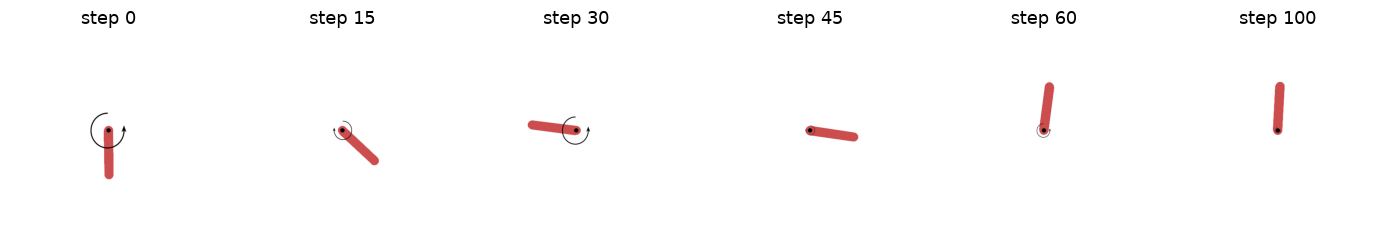

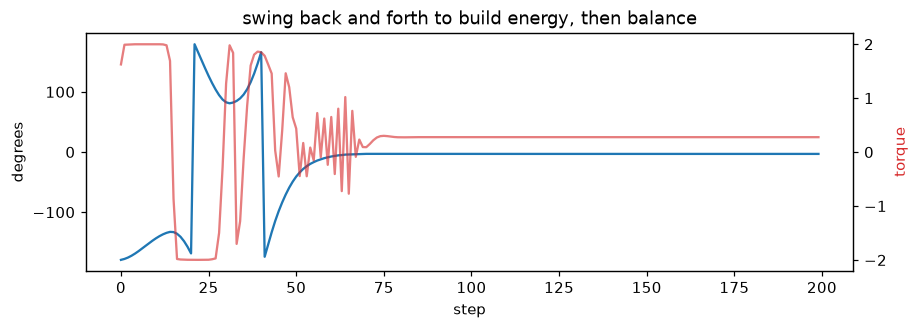

In [13]:
make_p = lambda: gym.make("Pendulum-v1")
t0 = time.time()
policy, log = sac.train(make_p(), total_steps=20_000, evaluate=evaluate_continuous(make_p), eval_every=4_000, seed=0)
print(f"({time.time() - t0:.0f} s)  returns during training: {[round(r['score']) for r in log]}")

env = gym.make("Pendulum-v1", render_mode="rgb_array")
obs, _ = env.reset(seed=0)
env.unwrapped.state = np.array([np.pi, 0.0])          # start hanging straight down
obs = np.array([-1.0, 0.0, 0.0], dtype=np.float32)
angles, torques, frames = [], [], []
for t in range(200):
    with torch.no_grad():
        action = policy.deterministic(torch.as_tensor(obs)[None])[0].numpy() * 2.0
    obs, reward, *_ = env.step(action)
    angles.append(np.arctan2(obs[1], obs[0])); torques.append(float(action[0]))
    if t in (0, 15, 30, 45, 60, 100):
        frames.append((t, env.render()))
fig, axs = plt.subplots(1, len(frames), figsize=(16, 2.8))
for ax, (t, f) in zip(axs, frames):
    ax.imshow(f); ax.set_title(f"step {t}"); ax.axis("off")
plt.show()
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(np.degrees(angles), label="angle (0 = upright)"); ax.set_ylabel("degrees")
ax2 = ax.twinx(); ax2.plot(torques, color="tab:red", alpha=0.6, label="torque"); ax2.set_ylabel("torque", color="tab:red")
ax.set_xlabel("step"); ax.set_title("swing back and forth to build energy, then balance"); plt.show()

## 9. What breaks, and how you would know

| method | symptom | likely cause |
| --- | --- | --- |
| REINFORCE | gradient norm swings by orders of magnitude | that is the variance of $G_t$; add a baseline (section 2) |
| + baseline | no better than plain | critic explained variance near 0: the baseline is noise |
| A2C | entropy → 0 early, return stalls | the policy went deterministic before finding anything; raise the entropy bonus |
| A2C / PPO | return capped below the time limit | truncation treated as termination (`a2c.py` folds γV(s) into the last reward) |
| PPO | clip fraction ≈ 0, KL ≈ 1e-4 | too few epochs or too small a learning rate: PPO is slow A2C |
| PPO | ratio ≠ 1 on the first minibatch | old log-probabilities stored from the wrong network |
| TRPO | every line search backtracks to the end | the policy never moves: wrong sign of g, or a Fisher product without `create_graph=True` (zero curvature) |
| TRPO | accepted KL above δ | the "old" distribution is not detached from before the step |
| DDPG / TD3 | mean Q climbs, return does not | actor exploiting critic overestimation |
| SAC | entropy far below target while α rises | tanh log-probability correction missing (`sac.py`, `TanhGaussian.sample`) |